# 06 · Le séisme du 16 avril 2016 : un banc d'essai pour la méthode, pas une promotion

Un choc exogène daté, à géographie connue : Manabí et Esmeraldas sont frappées ; le reste du pays tremble,
puis achète pour l'aide d'urgence (Kaggle le signale : « people rallied in relief efforts donating water and
other first need products which greatly affected supermarket sales for several weeks »). C'est l'occasion de
voir la méthode sur un effet qu'on sait réel, et surtout de voir ce qu'elle fait quand l'hypothèse
« contrôles non affectés » est **connue pour être fausse** : les magasins donneurs ont vendu plus, eux aussi.
Les chiffres viennent de `nr quake` (`data/results/quake.json`, `quake.pkl`).

In [1]:
import json
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from novaretail import viz
from novaretail.calendar import QUAKE, QUAKE_STATES
from novaretail.data import RESULTS
from novaretail.earthquake import DONOR_STATES
from novaretail.workspace import load_world

viz.setup()
export = viz.exporter("../figures")
rep = json.loads((RESULTS / "quake.json").read_text())
with open(RESULTS / "quake.pkl", "rb") as fh:
    q = pickle.load(fh)
w = load_world()
print("magasins traités :", rep["treated"], " donneurs :", rep["donors"])

magasins traités : [6, 7]  donneurs : [5, 8, 9]


## 1. La géographie du choc et le choix des donneurs

**Intuition.** Les unités traitées sont les magasins des deux provinces frappées. Les donneurs sont déclarés
**avant** de regarder les séries : provinces éloignées de l'épicentre, en excluant Pichincha (Quito) et
Guayas (Guayaquil), les deux pôles de collecte de l'aide, où l'interférence est la moins crédible. C'est le
même principe que le registre des campagnes : des règles, pas l'ajustement.

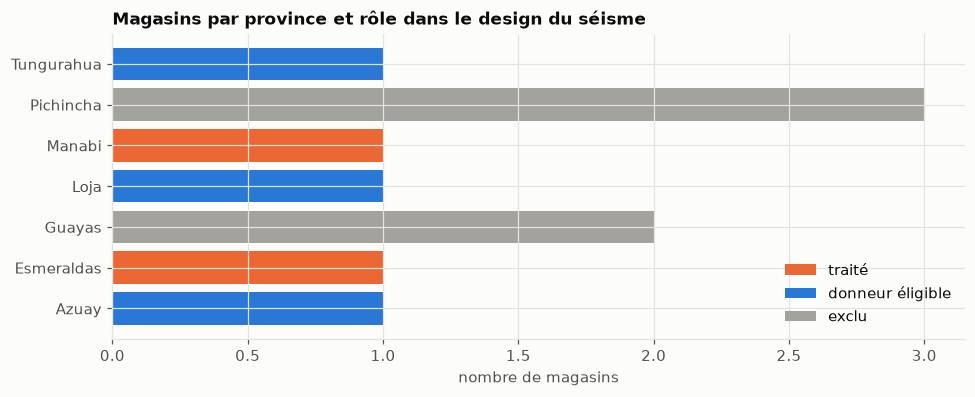

In [2]:
st = w.stores.copy()
st["rôle"] = np.select([st["state"].isin(QUAKE_STATES), st["state"].isin(DONOR_STATES)],
                       ["traité", "donneur éligible"], default="exclu")
byst = st.groupby(["state", "rôle"], observed=True).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(10, 0.3 * len(byst) + 1.5))
cols = {"traité": viz.ORANGE, "donneur éligible": viz.BLUE, "exclu": viz.MUTED}
left = np.zeros(len(byst))
for role, c in cols.items():
    if role in byst.columns:
        ax.barh(byst.index, byst[role], left=left, color=c, label=role)
        left += byst[role].values
ax.set_xlabel("nombre de magasins")
ax.set_title("Magasins par province et rôle dans le design du séisme")
ax.legend(loc="lower right")
export(fig, "nb06_geography")
plt.show()

## 2. Les séries et l'effet

**Exemple.** Total journalier des magasins traités (log) contre les magasins donneurs, six mois de pré-période,
huit semaines après. Puis les trois panneaux du contrefactuel.

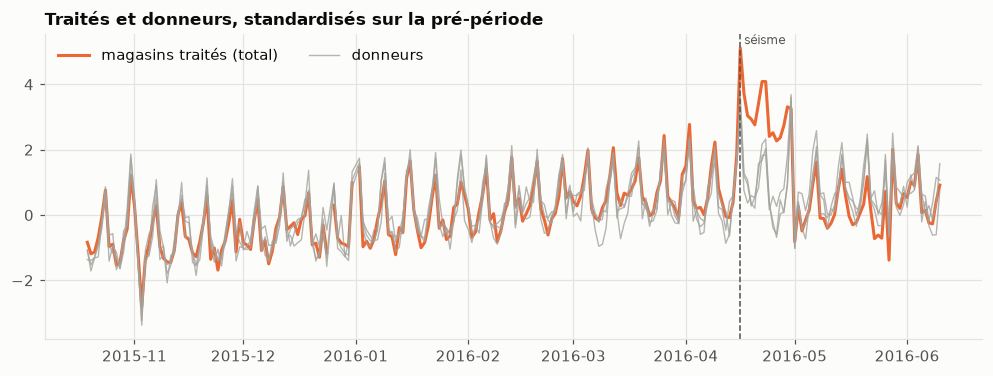

In [3]:
frame = q["frame"]


def z(s):
    return (s - s.loc[:QUAKE].mean()) / s.loc[:QUAKE].std()


fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(z(frame["treated"]), color=viz.ORANGE, label="magasins traités (total)")
for i, c in enumerate([c for c in frame.columns if c != "treated"]):
    ax.plot(z(frame[c]), color=viz.MUTED, linewidth=0.9, alpha=0.8, label="donneurs" if i == 0 else None)
viz.mark_intervention(ax, QUAKE, "séisme")
ax.set_title("Traités et donneurs, standardisés sur la pré-période")
ax.legend(loc="upper left", ncol=2)
export(fig, "nb06_series")
plt.show()

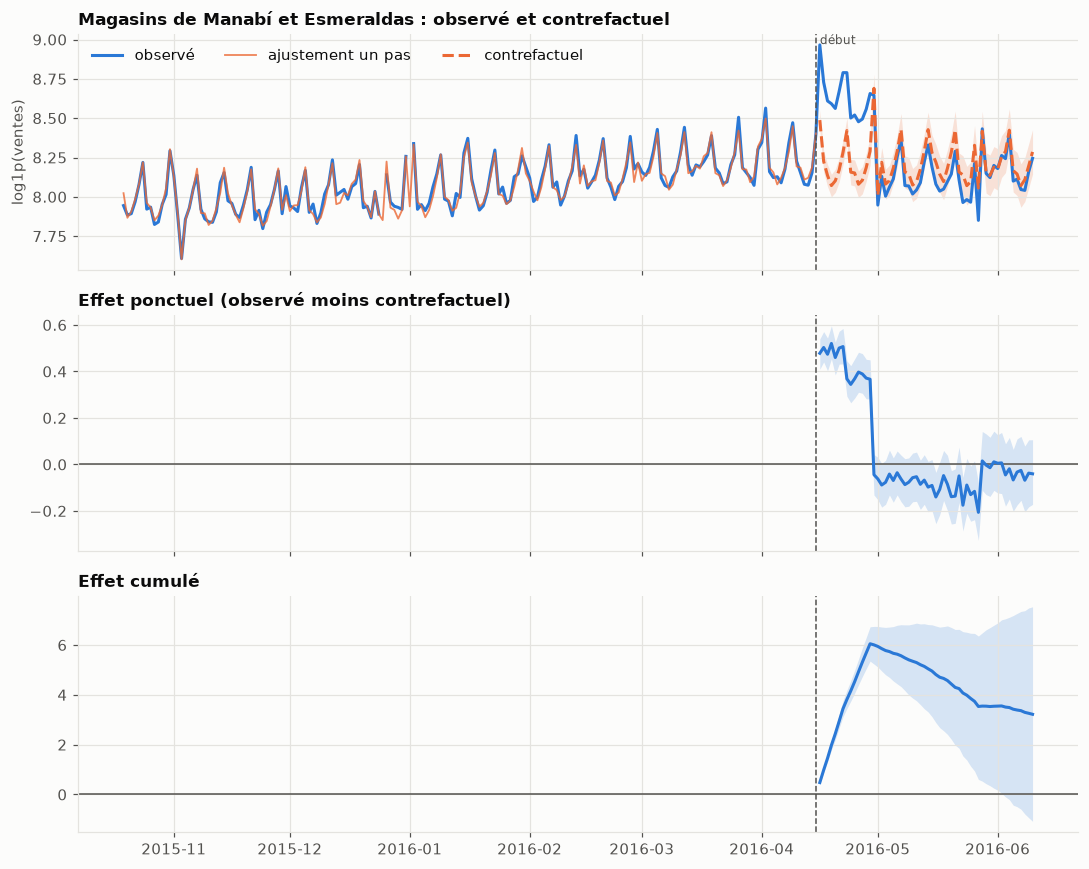

effet sur les 8 semaines, en unités : +8.9% [+0.6% ; +17.3%]


In [4]:
fig, axes = viz.plot_impact(q["result"], "Magasins de Manabí et Esmeraldas : observé et contrefactuel", figsize=(10, 8))
export(fig, "nb06_impact")
plt.show()
s = rep["summary"]
print(f"effet sur les 8 semaines, en unités : {s['units_rel']:+.1%} "
      f"[{s['units_rel_lower']:+.1%} ; {s['units_rel_upper']:+.1%}]")

**Intuition.** L'effet n'est pas une marche : une ruée la première semaine, puis une normalisation, voire un
creux (magasins endommagés, population déplacée). La lecture semaine par semaine, en unités à partir des
trajectoires, est la bonne échelle.

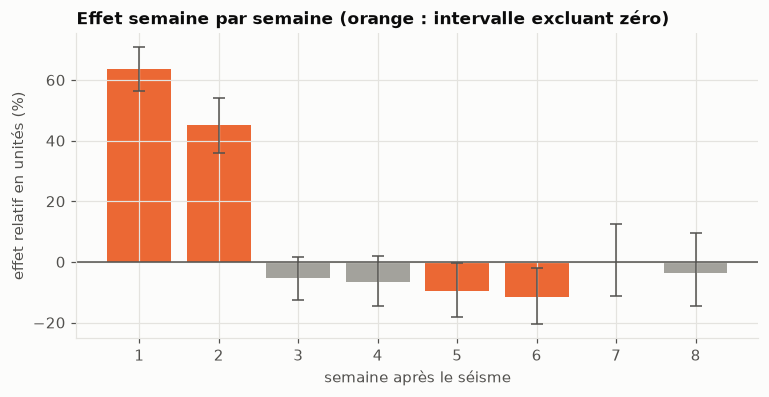

In [5]:
wk = q["weekly"]
fig, ax = plt.subplots(figsize=(8, 3.6))
flags = zip(wk["rel_lower"], wk["rel_upper"], strict=True)
colors = [viz.ORANGE if (lo > 0 or hi < 0) else viz.MUTED for lo, hi in flags]
ax.bar(wk.index, wk["rel_effect"] * 100, color=colors,
       yerr=[(wk["rel_effect"] - wk["rel_lower"]) * 100, (wk["rel_upper"] - wk["rel_effect"]) * 100], capsize=4,
       error_kw={"ecolor": viz.TEXT_2, "elinewidth": 1})
ax.axhline(0, color=viz.TEXT_2, linewidth=1)
ax.set_xlabel("semaine après le séisme")
ax.set_ylabel("effet relatif en unités (%)")
ax.set_title("Effet semaine par semaine (orange : intervalle excluant zéro)")
export(fig, "nb06_weekly")
plt.show()

## 3. Les placebos, et l'interférence qu'ils révèlent

**Attention.** Le placebo dans le temps (six fausses dates) valide le modèle de pré-période. Le placebo dans
l'espace fait de chaque magasin donneur la cible, avec les autres donneurs comme contrôles : si l'aide d'urgence
a fait acheter tout le pays, des donneurs auront un « effet propre » positif. C'est une violation **connue** de
SUTVA ; la méthode la voit ici parce qu'on sait où regarder, et l'effet estimé sur les provinces frappées est
alors une **borne basse** (les donneurs ont monté, le contrefactuel aussi).

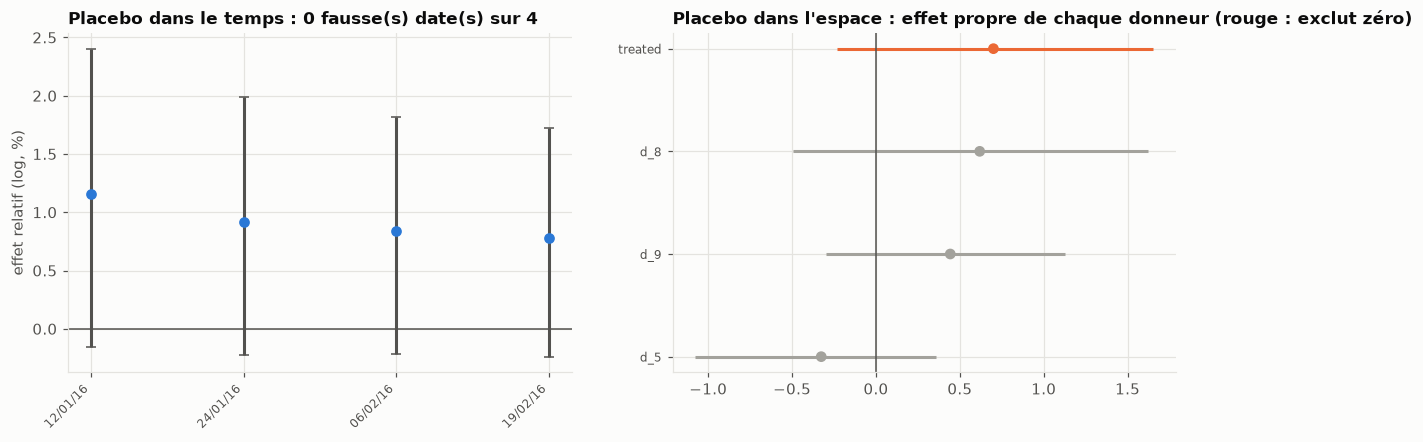

donneurs signalés : aucun


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sw = q["sweep"]
ax = axes[0]
x = np.arange(len(sw))
ax.errorbar(x, sw["rel_effect"] * 100, yerr=[(sw["rel_effect"] - sw["rel_lower"]) * 100,
            (sw["rel_upper"] - sw["rel_effect"]) * 100], fmt="o", color=viz.BLUE, ecolor=viz.TEXT_2, capsize=3)
ax.axhline(0, color=viz.TEXT_2, linewidth=1)
ax.set_xticks(x, [d.strftime("%d/%m/%y") for d in sw.index], rotation=45, ha="right", fontsize=8)
ax.set_title(f"Placebo dans le temps : {int(sw['excludes_zero'].sum())} fausse(s) date(s) sur {len(sw)}")
ax.set_ylabel("effet relatif (log, %)")
ax = axes[1]
sp = q["space"].sort_values("rel_effect")
ypos = np.arange(len(sp))
flags = zip(sp["is_treated"], sp["excludes_zero"], strict=True)
colors = [viz.ORANGE if t else (viz.CRITICAL if e else viz.MUTED) for t, e in flags]
ax.hlines(ypos, sp["rel_lower"] * 100, sp["rel_upper"] * 100, color=colors, linewidth=2)
ax.scatter(sp["rel_effect"] * 100, ypos, c=colors, zorder=3)
ax.axvline(0, color=viz.TEXT_2, linewidth=1)
ax.set_yticks(ypos, sp.index, fontsize=8)
ax.set_title("Placebo dans l'espace : effet propre de chaque donneur (rouge : exclut zéro)")
export(fig, "nb06_placebos")
plt.show()
print("donneurs signalés :", rep["donors_flagged"] or "aucun")

## 4. Quelles familles ont porté l'effet

**Exemple.** Même design, famille par famille (total des magasins traités contre total des donneurs de la même
famille, quatre semaines). Les familles de première nécessité devraient monter ; les achats différables baisser.

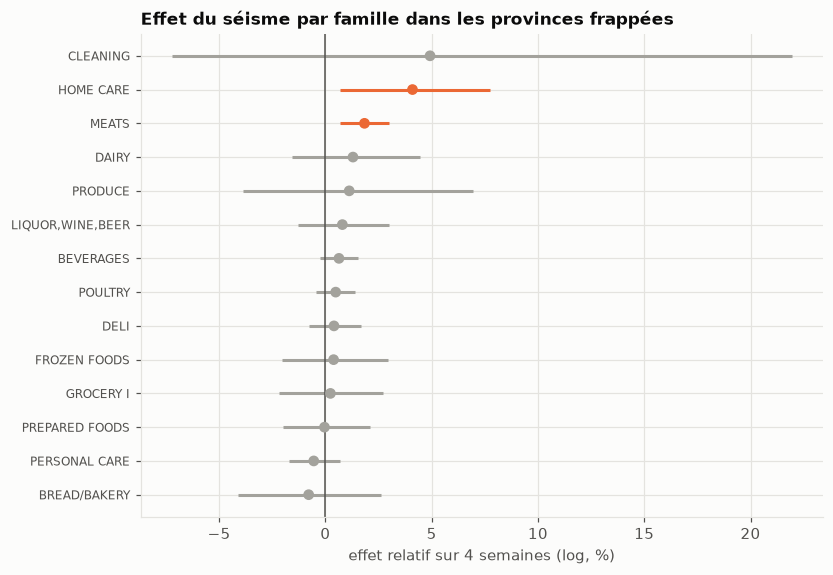

In [7]:
bf = q["by_family"].sort_values("rel_effect")
fig, ax = plt.subplots(figsize=(8, 0.3 * len(bf) + 1.5))
ypos = np.arange(len(bf))
colors = [viz.ORANGE if e else viz.MUTED for e in bf["excludes_zero"]]
ax.hlines(ypos, bf["rel_lower"] * 100, bf["rel_upper"] * 100, color=colors, linewidth=2)
ax.scatter(bf["rel_effect"] * 100, ypos, c=colors, zorder=3)
ax.axvline(0, color=viz.TEXT_2, linewidth=1)
ax.set_yticks(ypos, bf.index, fontsize=8)
ax.set_xlabel("effet relatif sur 4 semaines (log, %)")
ax.set_title("Effet du séisme par famille dans les provinces frappées")
export(fig, "nb06_by_family")
plt.show()

## À retenir

- Sur un choc réel et daté, la méthode trouve l'effet et sa forme (ruée puis normalisation).
- Quand les contrôles sont affectés, le placebo dans l'espace le montre **si l'on sait où regarder** ; l'effet
  estimé devient une borne basse. Sur une campagne promo, personne ne sait où regarder : d'où le registre.
- Le séisme n'entre pas dans le calendrier promo ; il n'est là que pour éprouver la méthode.